# 07 – Živý režim a stabilní součet

In [7]:
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))
from coins.io import load_rgb, show_images, DATASET_DIR
from coins.counter import CoinCounter
from coins.stabilize import Stabilizer
from live import draw

counter = CoinCounter(ROOT / "results" / "05_priznaky.csv")
ann = pd.read_csv(DATASET_DIR / "anotace.csv", sep=";")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Celý řetězec na testovacích fotkách

In [8]:
rows = []
for f in ann.soubor[ann.sada == "test"]:
    img = load_rgb(DATASET_DIR / f)
    t = time.perf_counter()
    coins = counter.process(img)
    ms = (time.perf_counter() - t) * 1000
    true = ann.loc[ann.soubor == f, "soucet"].item()
    rows.append({"soubor": f, "součet": true, "systém": sum(c["value"] for c in coins),
                 "mincí": len(coins), "ms": round(ms)})
res = pd.DataFrame(rows)
res["správně"] = res["součet"] == res["systém"]
print(f"přesný součet: {res['správně'].sum()}/{len(res)}, průměrně {res.ms.mean():.0f} ms na snímek "
      f"(~{1000 / res.ms.mean():.1f} snímků/s)")
res

přesný součet: 15/16, průměrně 40 ms na snímek (~25.0 snímků/s)


,soubor,součet,systém,mincí,ms,správně
0,test/test_01.jpg,234,234,14,92,True
1,test/test_02.jpg,83,83,10,36,True
2,test/test_03.jpg,83,83,10,36,True
3,test/test_04.jpg,83,83,10,35,True
4,test/test_05.jpg,183,183,12,37,True
5,test/test_06.jpg,203,203,13,38,True
6,test/test_07.jpg,253,253,14,41,True
7,test/test_08.jpg,258,258,15,42,True
8,test/test_09.jpg,152,152,11,38,True
9,test/test_10.jpg,227,227,11,38,True


## Simulované video: mince → ruka → jedna mince odebrána

In [9]:
def make_sequence(img_bgr, remove_xyr, n_before=40, n_hand=15, n_after=45, seed=0):
    rng = np.random.default_rng(seed)
    h, w = img_bgr.shape[:2]
    x, y, r = remove_xyr
    mask = np.zeros((h, w), np.uint8)
    cv2.circle(mask, (int(x), int(y)), int(r * 1.15), 255, -1)
    removed = cv2.inpaint(img_bgr, mask, 7, cv2.INPAINT_TELEA)
    frames, phase = [], []
    for i in range(n_before + n_hand + n_after):
        base = img_bgr if i < n_before + n_hand // 2 else removed
        M = np.float32([[1, 0, rng.normal(0, 1.5)], [0, 1, rng.normal(0, 1.5)]])
        f = cv2.warpAffine(base, M, (w, h), borderMode=cv2.BORDER_REFLECT)
        f = np.clip(f * rng.uniform(0.97, 1.03) + rng.normal(0, 3, f.shape), 0, 255).astype(np.uint8)
        if n_before <= i < n_before + n_hand:
            cx = int(-200 + (i - n_before) / (n_hand - 1) * (w + 400))
            cv2.ellipse(f, (cx, int(y)), (220, 120), -20, 0, 360, (120, 160, 220), -1)
            cv2.rectangle(f, (cx - 600, int(y) - 90), (cx - 100, int(y) + 60), (120, 160, 220), -1)
        frames.append(f)
        phase.append("mince" if i < n_before else "ruka" if i < n_before + n_hand else "bez 50 Kč")
    return frames, phase

frames, phase = make_sequence(cv2.imread(str(DATASET_DIR / "test/test_07.jpg")), (254, 674, 69))

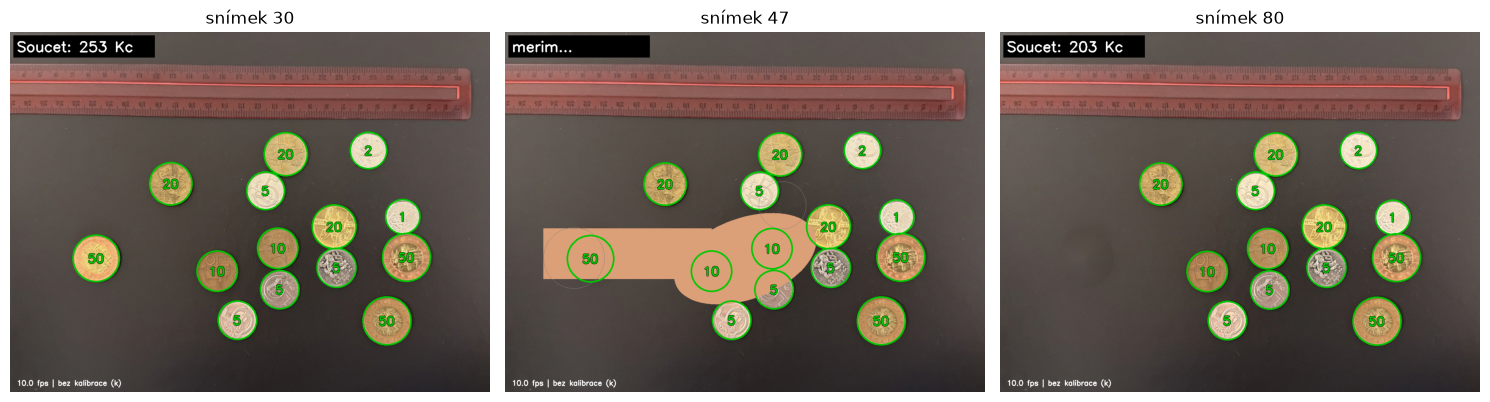

In [10]:
stab = Stabilizer()
log, shots = [], {}
for i, frame_bgr in enumerate(frames):
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    coins = counter.process(rgb)
    stable = stab.update(rgb, coins)
    log.append({"snímek": i, "fáze": phase[i], "surový": sum(c["value"] for c in coins),
                "stabilní": stable, "pohyb": stab.moving})
    if i in (30, 47, 80):
        vis = frame_bgr.copy()
        draw(vis, coins, stab, 10, None)
        shots[i] = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
log = pd.DataFrame(log)
show_images(list(shots.values()), [f"snímek {i}" for i in shots], cols=3, size=5)

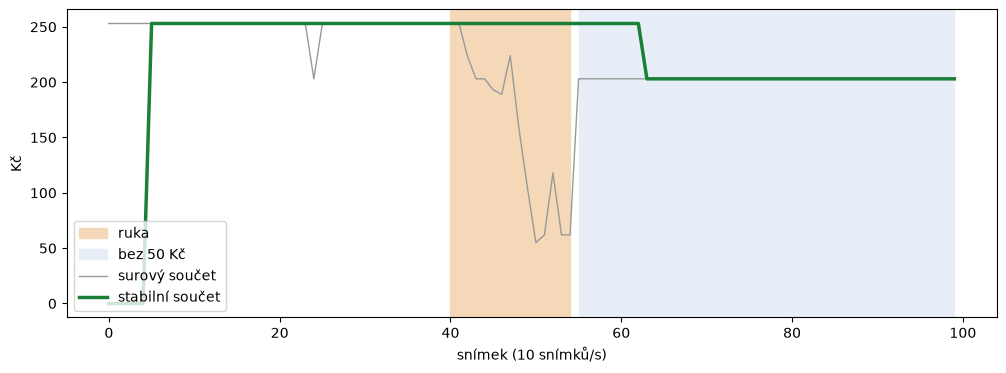

změn součtu: surový 14, stabilní 2
reakce na odebrání po odchodu ruky: 0.8 s


In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
for name, color in [("ruka", "#f4d8b8"), ("bez 50 Kč", "#e8eef8")]:
    idx = log.index[log["fáze"] == name]
    ax.axvspan(idx.min(), idx.max(), color=color, label=name)
ax.plot(log["snímek"], log["surový"], color="#999999", lw=1, label="surový součet")
ax.plot(log["snímek"], log["stabilní"], color="#1a7f37", lw=2.5, label="stabilní součet")
ax.set_xlabel("snímek (10 snímků/s)"); ax.set_ylabel("Kč"); ax.legend(loc="lower left")
plt.show()

changes = lambda s: int((s.diff().fillna(0) != 0).sum())
hand_end = log[log["fáze"] == "ruka"]["snímek"].max() + 1
first_203 = log[log["stabilní"] == 203]["snímek"].min()
print(f"změn součtu: surový {changes(log['surový'])}, stabilní {changes(log['stabilní'])}")
print(f"reakce na odebrání po odchodu ruky: {(first_203 - hand_end) / 10:.1f} s")

In [12]:
log.to_csv(ROOT / "results" / "07_simulace.csv", index=False)

## Reálná videa z iPhonu (14. 11., 4 videa, 4K → 1920 px, 10 snímků/s)
Zpracováno skriptem `python live.py --source video.mp4 --no-window --log results/07_video_<n>.csv`.
Ruka mince přidává a odebírá. Pro každý klidný úsek (bez pohybu, aspoň 0,6 s) je ručně ověřený správný součet.

In [13]:
calm = pd.read_csv(ROOT / "results" / "07_video_vyhodnoceni.csv")
print(f"klidných scén: {len(calm)}, stabilní součet nakonec správně: {calm['čas_do_správného_s'].notna().sum()}, "
      f"zpoždění medián {calm['čas_do_správného_s'].median():.1f} s, max {calm['čas_do_správného_s'].max():.1f} s")
calm

klidných scén: 19, stabilní součet nakonec správně: 19, zpoždění medián 0.4 s, max 0.8 s


,video,klid_od,klid_do,správně,raw_správně_%,stabilní_správně_%,čas_do_správného_s
0,6490,0.2,0.8,116,100,57,0.3
1,6490,2.2,3.4,106,92,62,0.5
2,6490,4.9,6.1,86,92,62,0.5
3,6490,7.4,8.2,106,56,56,0.4
4,6490,10.1,12.7,116,93,85,0.4
5,6491,0.2,0.9,116,75,62,0.3
6,6491,2.7,3.3,66,86,29,0.5
7,6491,4.8,5.9,64,83,83,0.2
8,6491,7.4,8.2,44,100,44,0.5
9,6491,9.4,10.5,64,75,33,0.8


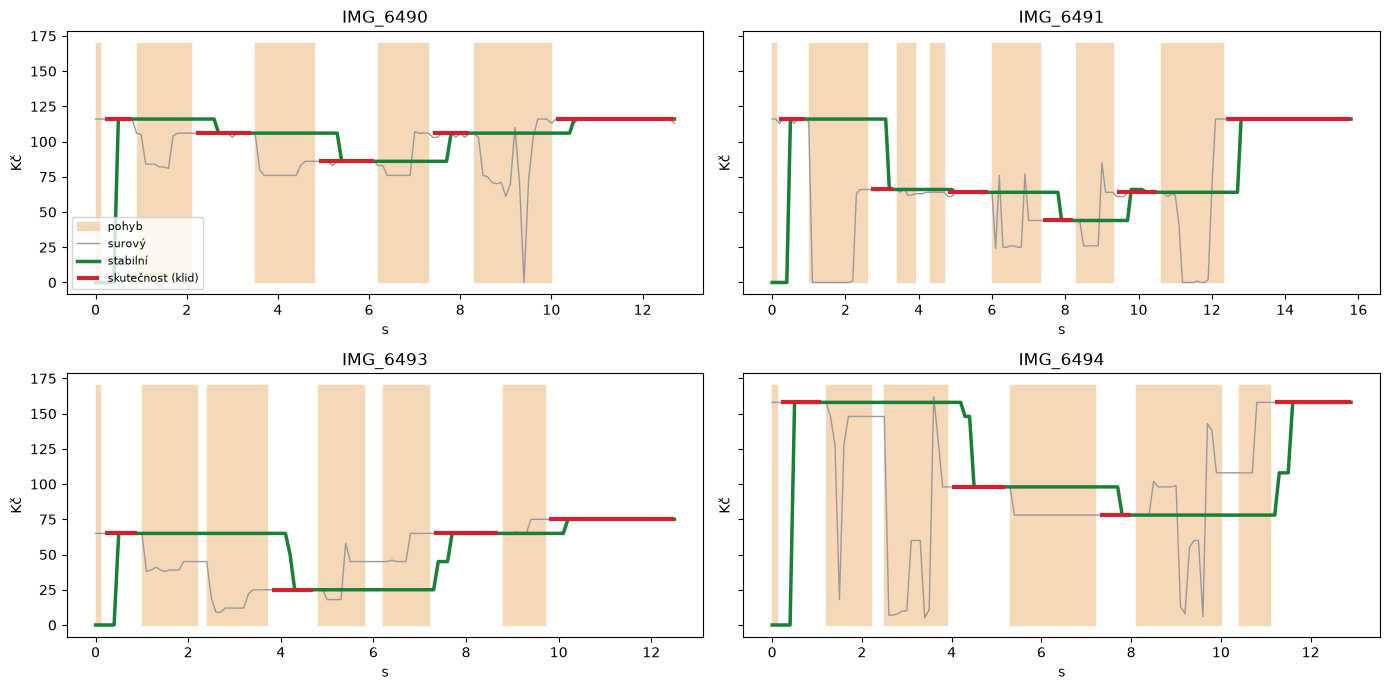

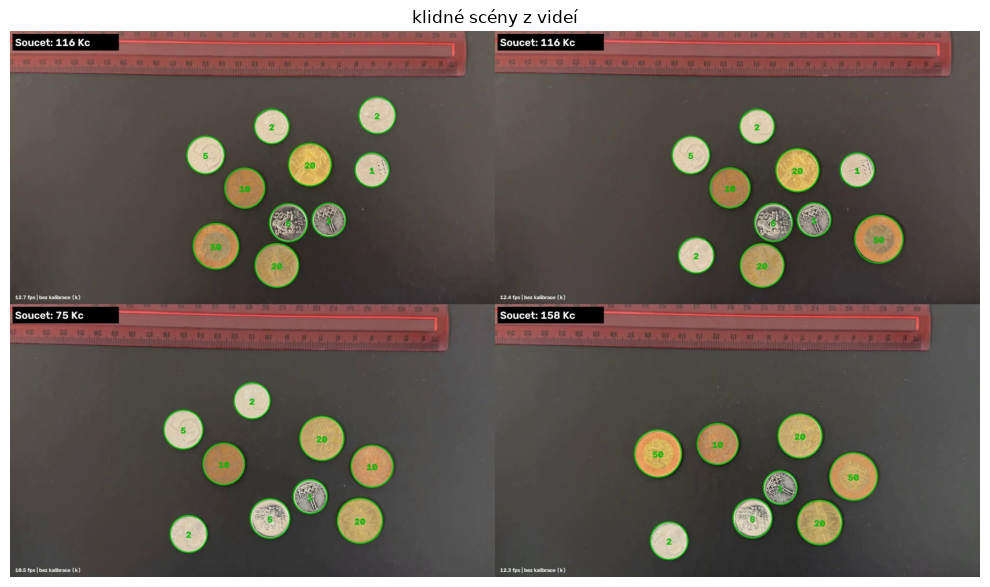

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=True)
for ax, n in zip(axes.ravel(), [6490, 6491, 6493, 6494]):
    d = pd.read_csv(ROOT / "results" / f"07_video_{n}.csv")
    ax.fill_between(d["cas_s"], 0, 170, where=d["pohyb"], color="#f4d8b8", step="mid", label="pohyb")
    ax.plot(d["cas_s"], d["surovy"], color="#999999", lw=1, label="surový")
    ax.plot(d["cas_s"], d["stabilni"], color="#1a7f37", lw=2.5, label="stabilní")
    c = calm[calm.video == n]
    ax.hlines(c["správně"], c["klid_od"], c["klid_do"], color="#cf222e", lw=3, label="skutečnost (klid)")
    ax.set_title(f"IMG_{n}"); ax.set_xlabel("s"); ax.set_ylabel("Kč")
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()
show_images([load_rgb(ROOT / "results" / "07_video_sceny.jpg")], ["klidné scény z videí"], size=10)

## Spuštění s kamerou
```
python live.py --list          # najde iPhone (Continuity Camera)
python live.py --source 1      # číslo kamery z --list
```
- Na podložku dát jen desetikoruny a stisknout **k** → kalibrace px/mm se uloží do `kalibrace.json`.
- **s** uloží snímek do `results/`, **q** konec.
- `--log results/07_kamera.csv --record results/07_kamera.mp4` uloží součty po snímcích a video pro vyhodnocení.

## Závěr
- `CoinCounter` přeškáluje každý snímek na měřítko datasetu (4,876 px/mm), takže platí stejné parametry detekce i klasifikátor (kNN, průměr + sytost).
- Příznaky se počítají jednou za snímek a jen ve výřezu kolem mince: 200 ms → 3 ms při 14 mincích, stejné hodnoty.
- Stabilizace: sledování mincí mezi snímky, hlasování o hodnotě, hystereze (přidat po 3 snímcích, odebrat po 3 chybějících), medián z 5 snímků a zmrazení při pohybu (> 2 % pixelů se změní).
- Simulace: surový součet se změní 15×, stabilní jen 2× (start a odebrání mince); během ruky drží 253 Kč, po odebrání ukáže 203 Kč do 1 s.
- Reálná videa z iPhonu: detekce zpočátku selhávala, protože ruka u okraje snímku „přetáhla“ práh watershedu → objekty u okraje se vyřazují a práh pro středy mincí je pevný (≈ 0,4 × poloměr 1 Kč). Na datasetu beze změny (476/476, test 160/161).
- Hraniční 20 Kč (25,5 mm, sytost 140 – víc než v trénovacích fotkách) se pletla s 10 Kč → hodnota stopy ze zprůměrovaných příznaků a průměr váží 2× víc než sytost. Na testu: mince 99,4 % (beze změny), EER průměr 2,7 % → 1,4 %, max 9,3 % → 7,1 %; boční světlo 74 % → 85 %. Váhu jsme volili podle videí, test byl při tom vidět → ověřit na nové testovací sadě.
- Videa: 19/19 klidných scén skončí na správném součtu, zpoždění po odchodu ruky medián 0,4 s, max 0,8 s.